In [ ]:
!pip install kaggle

In [ ]:
import kagglehub

# Download the latest version of the Face Mask Dataset from Kaggle
path = kagglehub.dataset_download("omkargurav/face-mask-dataset")

# Display the location where KaggleHub saved the dataset
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'face-mask-dataset' dataset.
Path to dataset files: /kaggle/input/face-mask-dataset


In [ ]:
import os

# Show the files and folders inside the downloaded dataset
print(os.listdir(path))

['data']


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [ ]:
import os

dataset_path = path
# Create paths for both classes
with_mask_path = os.path.join(dataset_path, "with_mask")
without_mask_path = os.path.join(dataset_path, "without_mask")
print("with mask path:", with_mask_path)
print("without mask path:",without_mask_path)

with mask path: /kaggle/input/face-mask-dataset/with_mask
without mask path: /kaggle/input/face-mask-dataset/without_mask


In [ ]:
 # Correct the dataset_path to include the 'data' subdirectory
 dataset_path_corrected = os.path.join(path, "data")

 # Create corrected paths for both classes
 with_mask_path = os.path.join(dataset_path_corrected, "with_mask")
 without_mask_path = os.path.join(dataset_path_corrected, "without_mask")

 # Count the images
 with_mask_count = len(os.listdir(with_mask_path))
 without_mask_count = len(os.listdir(without_mask_path))
 print("Images with mask:", with_mask_count)
 print("Images without mask:", without_mask_count)

Images with mask: 3725
Images without mask: 3828


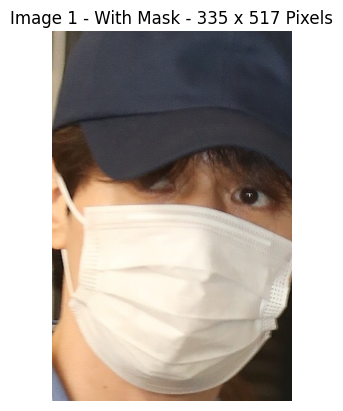

In [ ]:
from tensorflow.keras.utils import load_img

# Get the first image from the with_mask folder
image_name = os.listdir(with_mask_path)[4]

# Create the complete image path
image_path = os.path.join(with_mask_path, image_name)

# Load the image
image = load_img(image_path)

# Get image width and height
width, height = image.size

# Display the image
plt.imshow(image)

# Show image number and pixel size in title
plt.title(f"Image 1 - With Mask - {width} x {height} Pixels")

plt.axis("off")
plt.show()

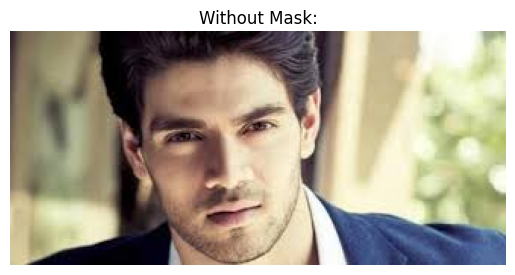

In [ ]:
# Get the first image from the with_mask folder
image_name = os.listdir(without_mask_path)[7]

# Create the complete image path
image_path = os.path.join(without_mask_path, image_name)

# Load and display the image
image = load_img(image_path)
plt.imshow(image)
plt.title(f"Without Mask:")
plt.axis("off")
plt.show()

In [ ]:
# ImageDataGenerator prepares images for CNN training
datagen = ImageDataGenerator(
    rescale = 1./255,
    validation_split = 0.2
)

In [ ]:
# create traning data
train_data = datagen.flow_from_directory(
    dataset_path_corrected,
    target_size = (128, 128),
    batch_size = 32,
    class_mode = "binary",
    subset = "training"

)

Found 6043 images belonging to 2 classes.


In [ ]:
target_size = (150, 150)
batch_size = 32
class_mode = "binary"
subset = "validation"


In [ ]:
# create validatoin data
validation_data = datagen.flow_from_directory(
    dataset_path_corrected,
    target_size = (128, 128),
    batch_size = 32,
    class_mode = "binary",
    subset = "validation"

)

Found 1510 images belonging to 2 classes.


In [ ]:
# check_class label
print(train_data.class_indices)

{'with_mask': 0, 'without_mask': 1}


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Create the CNN model
model = Sequential()

# First convolution layer
model.add(Conv2D(
    32,
    (3, 3),
    activation="relu",
    input_shape=(128, 128, 3)
))

# Max pooling layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Second convolution layer
model.add(Conv2D(
    64,
    (3, 3),
    activation="relu"
))

# Max pooling layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Convert the 2D feature maps into a 1D vector
model.add(Flatten())

# Fully connected layer
model.add(Dense(128, activation="relu"))

# Dropout layer to reduce overfitting
model.add(Dropout(0.5))

# Output layer
# Sigmoid gives a value between 0 and 1
model.add(Dense(1, activation="sigmoid"))

# Display the CNN architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compile CNN model
model.compile(
    optimizer = "adam",
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

print("model compile successfully")

model compile successfully


In [ ]:
# train it
history = model.fit(
    train_data,
    epochs = 15,
    validation_data = validation_data
)

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


189/189 ━━━━━━━━━━━━━━━━━━━━ 168s 886ms/step - accuracy: 0.9892 - loss: 0.0351 - val_accuracy: 0.9377 - val_loss: 0.2979
Epoch 2/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 167s 884ms/step - accuracy: 0.9924 - loss: 0.0225 - val_accuracy: 0.9325 - val_loss: 0.3501
Epoch 3/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 168s 889ms/step - accuracy: 0.9926 - loss: 0.0261 - val_accuracy: 0.9358 - val_loss: 0.3416
Epoch 4/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 166s 880ms/step - accuracy: 0.9911 - loss: 0.0244 - val_accuracy: 0.9238 - val_loss: 0.3986
Epoch 5/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 165s 873ms/step - accuracy: 0.9907 - loss: 0.0289 - val_accuracy: 0.9364 - val_loss: 0.3148
Epoch 6/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 205s 890ms/step - accuracy: 0.9959 - loss: 0.0139 - val_accuracy: 0.9411 - val_loss: 0.3401
Epoch 7/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 165s 872ms/step - accuracy: 0.9944 - loss: 0.0208 - val_accuracy: 0.9430 - val_loss: 0.2845
Epoch 8/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 164s 870ms/step - accuracy: 0.9974 - loss: 0.00

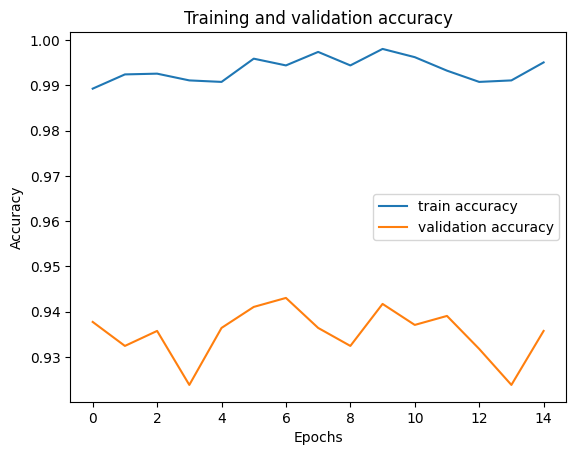

In [ ]:
plt.plot(history.history["accuracy"],
         label = "train accuracy")
plt.plot(history.history["val_accuracy"],
         label = "validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.show()

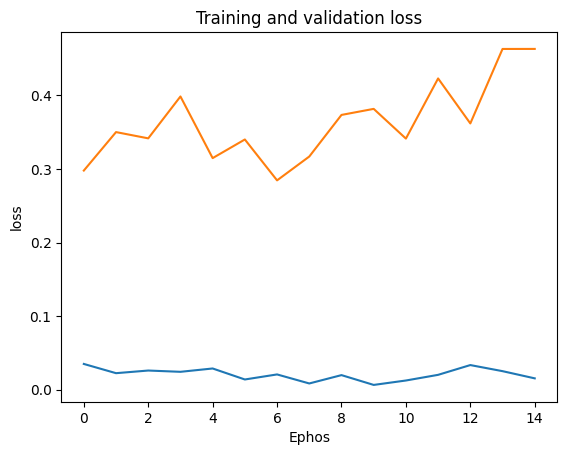

In [ ]:
# plot for training and validaton loss
plt.plot(history.history["loss"], label = "train loss")
plt.plot(history.history["val_loss"], label = "validation loss")

plt.xlabel("Ephos")
plt.ylabel("loss")
plt.title("Training and validation loss")
plt.legend
plt.show()